# Costruisci il dataset di articoli (tentativo 12: ottobre + terzo giro)

Il notebook dei tentativi 05–09, con due differenze: legge la cartella unita `Dataset/NuovoScraping/` (i due giri
di ottobre più il terzo giro del 25 ottobre, uniti da `unisci.sh`) e le etichette vengono dalle valutazioni
NewsGuard **2026** (`newsguard_2026.csv`; le poche testate di ottobre senza un punteggio 2026 restano senza
etichetta: i passi successivi le scartano). Filtri invariati: più di 100 parole, niente doppioni nella stessa
testata, solo inglese.


In [1]:
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt
from langdetect import detect, DetectorFactory, LangDetectException

CARTELLA = "../Dataset/NuovoScraping/"
NEWSGUARD = "../Dataset/newsguard_2026.csv"
LIVELLI = ["l1", "l2", "l3", "l4", "l5"]

## 1. Com'è andato lo scraping

Una riga di stato per ogni testata tentata.

In [2]:
stato = pd.DataFrame([json.load(open(f)) for f in glob.glob(CARTELLA + "stato/*.json")])
stato["esito breve"] = stato.esito.str.replace(r" \(.*\)", "", regex=True)
print(len(stato), "testate tentate")
print(json.load(open(CARTELLA + "config.json"))["versioni"])
stato.esito.value_counts().head(8)

5113 testate tentate
{'python': '3.11.5', 'trafilatura': '2.3.1', 'requests': '2.34.2', 'feedparser': '6.0.14', 'lxml': '6.1.3', 'pandas': '3.0.6'}


esito
esauriti gli URL o i tentativi                1653
homepage irraggiungibile (403)                1444
completata                                    1049
homepage irraggiungibile (ConnectionError)     707
homepage irraggiungibile (451)                  74
homepage irraggiungibile (503)                  46
homepage irraggiungibile (ConnectTimeout)       32
homepage irraggiungibile (404)                  24
Name: count, dtype: int64

## 2. Gli articoli e i filtri

In [3]:
articoli = pd.DataFrame([json.loads(riga) for f in sorted(glob.glob(CARTELLA + "articoli/*.jsonl")) for riga in open(f)])
passi = [("testi estratti", len(articoli), articoli.dominio.nunique())]

articoli = articoli[articoli.parole > 100]
passi.append(("più di 100 parole", len(articoli), articoli.dominio.nunique()))

articoli = articoli.drop_duplicates(["dominio", "url"]).drop_duplicates(["dominio", "testo"])
passi.append(("senza doppioni nella stessa testata", len(articoli), articoli.dominio.nunique()))

In [4]:
DetectorFactory.seed = 0

def lingua(testo):
    try:
        return detect(testo)
    except LangDetectException:
        return "?"

# solo sulle prime 400 parole: più veloce e sufficiente per riconoscere la lingua
articoli["lingua"] = articoli.testo.str.split().str[:400].str.join(" ").map(lingua)
print(articoli.lingua.value_counts().head(6).to_string())
articoli = articoli[articoli.lingua == "en"]
passi.append(("solo inglese", len(articoli), articoli.dominio.nunique()))
pd.DataFrame(passi, columns=["passo", "articoli", "testate"]).set_index("passo")

lingua
en    189189
de     33423
it     18115
fr     16824
ru      1819
es      1513


,articoli,testate
passo,,
testi estratti,299658,2409
più di 100 parole,264203,2381
senza doppioni nella stessa testata,264125,2381
solo inglese,189189,1957


## 3. Le etichette NewsGuard e la composizione

In [5]:
ng = pd.read_csv(NEWSGUARD, low_memory=False)
ng = ng.assign(Domain=ng.Domain.str.lower()).drop_duplicates("Domain").set_index("Domain")
livello = lambda serie: pd.cut(serie.map(ng.Score), [-1, 39, 59, 74, 99, 100], labels=[0, 1, 2, 3, 4]).astype("Int64")      # senza punteggio 2026: vuota
articoli["score"] = articoli.dominio.map(ng.Score)
articoli["label"] = livello(articoli.dominio)
stato["label"] = livello(stato.dominio)

per_testata = articoli.groupby("dominio").size()
composizione = pd.DataFrame({
    "testate tentate": stato.groupby("label").size(),          # le testate senza punteggio 2026 non sono contate
    "testate raggiunte": stato[~stato.esito.str.startswith("homepage")].groupby("label").size(),
    "testate nel dataset": articoli.groupby("label").dominio.nunique(),
    "con almeno 10 articoli": per_testata[per_testata >= 10].index.map(articoli.groupby("dominio").label.first()).value_counts(),
    "con almeno 20 articoli": per_testata[per_testata >= 20].index.map(articoli.groupby("dominio").label.first()).value_counts(),
    "articoli": articoli.groupby("label").size(),
}).fillna(0).astype(int).rename(index=lambda k: LIVELLI[k])
composizione.loc["totale"] = composizione.sum()
composizione

,testate tentate,testate raggiunte,testate nel dataset,con almeno 10 articoli,con almeno 20 articoli,articoli
l1,2951,1227,950,746,633,51252
l2,733,387,286,264,255,43542
l3,203,158,94,81,80,13829
l4,872,674,484,464,448,57847
l5,265,210,112,100,99,17646
totale,5024,2656,1926,1655,1515,184116


Quasi tutte le testate bloccate (HTTP 403) sono siti di una sola rete $l_1$ con lo stesso proprietario:

In [6]:
stato["proprietario"] = stato.dominio.map(ng.Owner)
rete = stato.proprietario == "Metric Media LLC"
print(f"siti della rete: {rete.sum()}, raggiunti: {(rete & ~stato.esito.str.startswith('homepage')).sum()}")
print(f"testate bloccate (403) fuori dalla rete: {(~rete & stato.esito.str.contains('403')).sum()} su {(~rete).sum()}")

siti della rete: 1082, raggiunti: 5
testate bloccate (403) fuori dalla rete: 382 su 4031


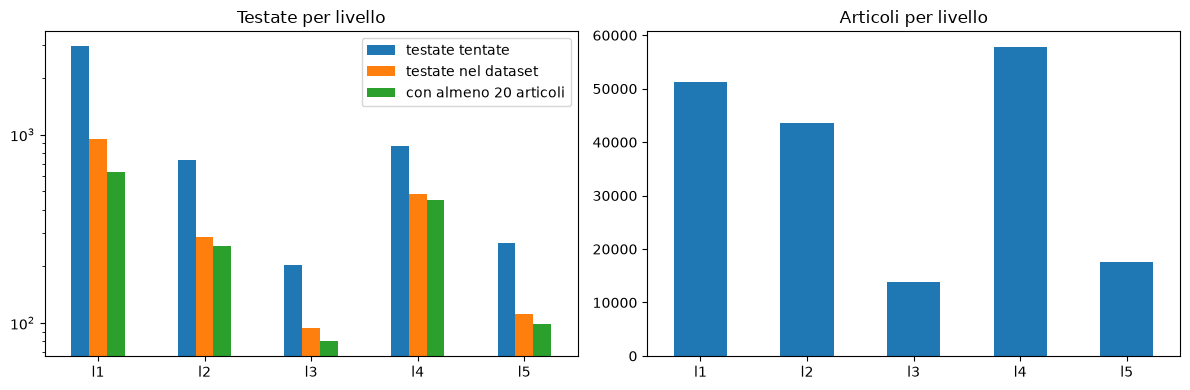

In [7]:
fig, assi = plt.subplots(1, 2, figsize=(12, 4))
composizione.drop("totale")[["testate tentate", "testate nel dataset", "con almeno 20 articoli"]].plot.bar(ax=assi[0], rot=0)
assi[0].set_title("Testate per livello"); assi[0].set_yscale("log")
composizione.drop("totale")["articoli"].plot.bar(ax=assi[1], rot=0, color="tab:blue")
assi[1].set_title("Articoli per livello")
plt.tight_layout(); plt.show()

## 4. Le date degli articoli

articoli con una data: 100%
count                        189185
mean     2025-04-14 22:33:17.777836
min             1995-02-01 00:00:00
25%             2025-09-26 00:00:00
50%             2026-09-21 00:00:00
75%             2026-10-14 00:00:00
max             2026-10-25 00:00:00
Name: data, dtype: object


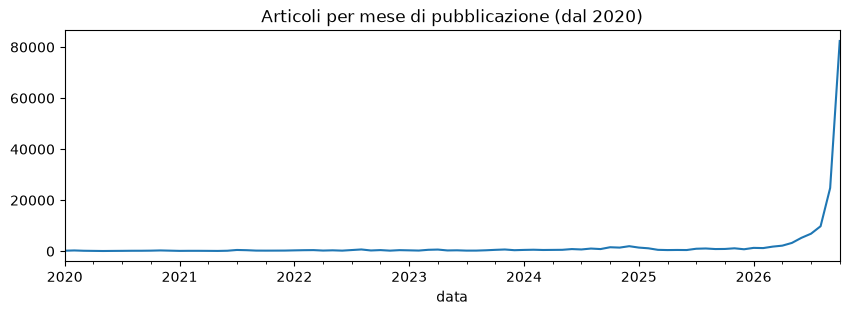

In [8]:
data = pd.to_datetime(articoli.data, errors="coerce")
print(f"articoli con una data: {data.notna().mean():.0%}")
print(data.describe())
data[data >= "2020-01-01"].dt.to_period("M").value_counts().sort_index().plot(figsize=(10, 3), title="Articoli per mese di pubblicazione (dal 2020)")
plt.show()

## 5. Confronto con il dataset vecchio (IrForGood)

In [9]:
# confronto (facoltativo) con il dataset di IrForGood, che sta nel tentativo 01
from pathlib import Path
VECCHIO = Path("../../01_PrimoDataset/Dataset/CleannedDataset/newDataframeWithOldCleanedPoliticsVersion.csv")
if VECCHIO.exists():
    vecchio = pd.read_csv(VECCHIO, usecols=["domain"]).domain
    nuove, vecchie = set(articoli.dominio), set(vecchio)
    print("testate in entrambi:", len(nuove & vecchie))
    print("solo nel nuovo:", len(nuove - vecchie))
    print("solo nel vecchio:", len(vecchie - nuove))
else:
    print("il dataset di IrForGood (tentativo 01) non c'è: confronto saltato")

il dataset di IrForGood (tentativo 01) non c'è: confronto saltato


## 6. Salvataggio

In [10]:
colonne = ["dominio", "url", "titolo", "data", "autore", "fonte", "parole", "testo", "score", "label"]
articoli[colonne].reset_index(drop=True).rename_axis("article_id").to_csv(CARTELLA + "dataset_articoli.csv")
print(len(articoli), "articoli,", articoli.dominio.nunique(), "testate")

189189 articoli, 1957 testate
